In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install kagglehub

In [ ]:
import kagglehub
import os

# Download dataset
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Dataset downloaded at:", path)
print("Files inside dataset:", os.listdir(path))


Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Dataset downloaded at: /kaggle/input/brain-tumor-mri-dataset
Files inside dataset: ['Training', 'Testing']


In [ ]:
train_dir = os.path.join(path, "Training")
test_dir  = os.path.join(path, "Testing")

print("Training classes:", os.listdir(train_dir))
print("Testing classes :", os.listdir(test_dir))



Training classes: ['pituitary', 'notumor', 'meningioma', 'glioma']
Testing classes : ['pituitary', 'notumor', 'meningioma', 'glioma']


In [ ]:
import torch
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import numpy as np
import os
import zipfile

import torch.nn as nn
import torch.optim as optim

import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder # Useful for loading image datasets from folders

import matplotlib.pyplot as plt

import shutil # For potential cleanup or moving files


In [ ]:
import os
from torchvision import transforms
from torchvision.datasets import ImageFolder

# Correct dataset paths
train_data_dir = os.path.join(path, "Training")
test_data_dir  = os.path.join(path, "Testing")

# Transformations
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor()
])

# Load datasets
train_dataset = ImageFolder(root=train_data_dir, transform=transform)
test_dataset  = ImageFolder(root=test_data_dir, transform=transform)

# Number of classes
num_classes = len(train_dataset.classes)

# Prepare lists (as in your original code)
x = []
y = []
x_test = []
y_test = []

print("Classes:", train_dataset.classes)


Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:

# Process training data
for img_tensor, label_idx in train_dataset:
    # Convert image tensor (1, H, W) to a NumPy array (H, W)
    img_array = img_tensor.squeeze().numpy()
    x.append(img_array)

    # Convert integer label to a one-hot vector of size num_classes
    one_hot_label = np.zeros(num_classes, dtype=np.float32)
    one_hot_label[label_idx] = 1.0
    y.append(one_hot_label)

# Process testing data
for img_tensor, label_idx in test_dataset:
    # Convert image tensor (1, H, W) to a NumPy array (H, W)
    img_array = img_tensor.squeeze().numpy()
    x_test.append(img_array)

    # Convert integer label to a one-hot vector of size num_classes
    one_hot_label = np.zeros(num_classes, dtype=np.float32)
    one_hot_label[label_idx] = 1.0
    y_test.append(one_hot_label)

# Convert lists of arrays to single NumPy arrays
x = np.array(x)
y = np.array(y)
x_test = np.array(x_test)
y_test = np.array(y_test)

In [ ]:

print(f"Training images shape (x): {x.shape}")
print(f"Training labels shape (y): {y.shape}")
print(f"Testing images shape (x_test): {x_test.shape}")
print(f"Testing labels shape (y_test): {y_test.shape}")
print(f"Number of classes detected: {num_classes}")

Training images shape (x): (5712, 256, 256)
Training labels shape (y): (5712, 4)
Testing images shape (x_test): (1311, 256, 256)
Testing labels shape (y_test): (1311, 4)
Number of classes detected: 4


Label vector (one-hot) for sample index 2762: [0. 0. 1. 0.]
Label vector (one-hot) for sample index 4754: [0. 0. 0. 1.]
Label vector (one-hot) for sample index 4834: [0. 0. 0. 1.]
Label vector (one-hot) for sample index 254: [1. 0. 0. 0.]
Label vector (one-hot) for sample index 1164: [1. 0. 0. 0.]


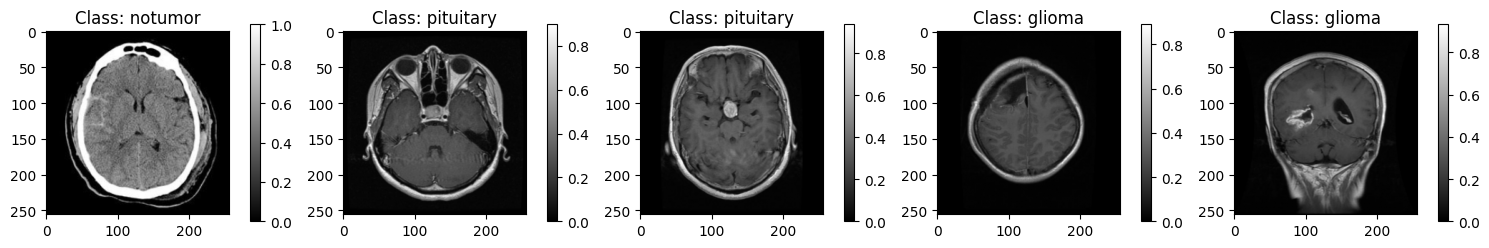

In [ ]:
import random

# Get class names from the train_dataset
class_names = train_dataset.classes

# Number of samples to plot
num_samples_to_plot = 5

# Generate random indices
random_indices = random.sample(range(len(x)), num_samples_to_plot)

for n in random_indices:
    print(f"Label vector (one-hot) for sample index {n}: {y[n]}")

# Plot the randomly selected samples with colorbars
plt.figure(figsize=(15, 5))
for i, idx in enumerate(random_indices):
    ax = plt.subplot(1, num_samples_to_plot, i + 1)
    img = plt.imshow(x[idx], cmap='gray') # Images are grayscale
    plt.colorbar(img, ax=ax, pad=0.1, fraction=0.046, aspect=20) # Add colorbar for the current image


    # Convert one-hot label back to class name
    label_index = np.argmax(y[idx])
    plt.title(f"Class: {class_names[label_index]}") # Display label as title
    # Removed plt.axis('off') to show axes

plt.tight_layout()
plt.show()

In [ ]:
print(f"Type of x: {type(x)}")
print(f"Shape of x: {x.shape}")
print(f"Range of values in x: [{np.min(x):.4f}, {np.max(x):.4f}]")
print("-" * 30)
print(f"Type of y: {type(y)}")
print(f"Shape of y: {y.shape}")
print(f"Range of values in y: [{np.min(y):.4f}, {np.max(y):.4f}]")

Type of x: <class 'numpy.ndarray'>
Shape of x: (5712, 256, 256)
Range of values in x: [0.0000, 1.0000]
------------------------------
Type of y: <class 'numpy.ndarray'>
Shape of y: (5712, 4)
Range of values in y: [0.0000, 1.0000]


In [ ]:
x = np.expand_dims(x, axis=1)
x_test = np.expand_dims(x_test, axis=1)

print(f"New training images shape (x): {x.shape}")
print(f"New testing images shape (x_test): {x_test.shape}")

New training images shape (x): (5712, 1, 256, 256)
New testing images shape (x_test): (1311, 1, 256, 256)


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader, random_split

class BrainTumorDataset(Dataset):
    def __init__(self, images, labels):
        # CHANGE 1: ensure correct dtype and contiguous memory
        self.images = torch.from_numpy(images).float().contiguous()
        self.labels = torch.from_numpy(labels).float()

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.labels[idx]


# Create dataset instances
train_dataset_torch = BrainTumorDataset(x, y)
test_dataset_torch = BrainTumorDataset(x_test, y_test)

# Define batch size
batch_size = 64

# Split the training dataset into training and validation sets
val_size = int(0.1 * len(train_dataset_torch))  # 10% for validation
train_size = len(train_dataset_torch) - val_size

# CHANGE 2: fixed random seed for reproducibility
generator = torch.Generator().manual_seed(42)

train_dataset_torch, val_dataset_torch = random_split(
    train_dataset_torch,
    [train_size, val_size],
    generator=generator
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset_torch,
    batch_size=batch_size,
    shuffle=True,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset_torch,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset_torch,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=True
)

print(f"Number of training samples: {len(train_dataset_torch)}")
print(f"Number of validation samples: {len(val_dataset_torch)}")
print(f"Number of testing samples: {len(test_dataset_torch)}")
print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

# Example of fetching a batch
for images, labels in train_loader:
    print(f"Shape of a batch of images: {images.shape}")
    print(f"Shape of a batch of labels: {labels.shape}")
    break


Number of training samples: 5141
Number of validation samples: 571
Number of testing samples: 1311
Number of training batches: 81
Number of validation batches: 9
Number of testing batches: 21
Shape of a batch of images: torch.Size([64, 1, 256, 256])
Shape of a batch of labels: torch.Size([64, 4])


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F



class SEBlock(nn.Module):
    def __init__(self, channels, reduction=16):
        super(SEBlock, self).__init__()
        self.fc1 = nn.Linear(channels, channels // reduction)
        self.fc2 = nn.Linear(channels // reduction, channels)

    def forward(self, x):
        b, c, _, _ = x.size()
        y = F.adaptive_avg_pool2d(x, 1).view(b, c)
        y = F.relu(self.fc1(y))
        y = torch.sigmoid(self.fc2(y)).view(b, c, 1, 1)
        return x * y

class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Identity()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

        self.se = SEBlock(out_channels)  # 🔥 STEP-6: Attention

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        out = self.se(out)              # 🔥 Amplify Learning
        return F.relu(out)

class CNNModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        # STEP-1 & STEP-2: Depth + Width
        self.in_channels = 32

        self.conv1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.layer1 = self._make_layer(32, 2, 1)
        self.layer2 = self._make_layer(64, 2, 2)
        self.layer3 = self._make_layer(128, 2, 2)
        self.layer4 = self._make_layer(256, 2, 2)

        # STEP-4: Global pooling
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        self.fc = nn.Linear(256, num_classes)

    def _make_layer(self, out_channels, blocks, stride):
        layers = [BasicBlock(self.in_channels, out_channels, stride)]
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(BasicBlock(out_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


model = CNNModel(num_classes=num_classes).to(device)
print(model)



CNNModel(
  (conv1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Identity()
      (se): SEBlock(
        (fc1): Linear(in_features=32, out_features=2, bias=True)
        (fc2): Linear(in_features=2, out_features=32, bias=True)
      )
    )
    (1): BasicBlock(
      (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), pad

Amplification


In [ ]:

class_weights = torch.tensor([1.2, 1.2, 1.5, 1.1]).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)


learning_rate = 0.0001

optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.1,
    patience=3
)


In [ ]:
class EarlyStopping:
    """
    Early stops the training if validation loss doesn't improve after a given patience.
    """
    def __init__(self, patience=7, min_delta=0.0005):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        val_loss = float(val_loss)

        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

        return self.early_stop
early_stopping = EarlyStopping(patience=7, min_delta=0.0005)


In [ ]:
class BrainTumorDataset(Dataset):
    def __init__(self, images, labels):
        self.images = torch.from_numpy(images).float()
        self.labels = torch.from_numpy(labels).float()

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = self.images[idx]

        # 🔥 CRITICAL FIX 🔥
        # If image is (64, 256, 256), keep ONLY ONE channel
        if image.dim() == 3:
            image = image[0].unsqueeze(0)   # → (1, 256, 256)

        # If image is (256, 256)
        elif image.dim() == 2:
            image = image.unsqueeze(0)      # → (1, 256, 256)

        return image, self.labels[idx]


Starting training on cuda for 50 epochs...
Epoch 29/50 | Train Loss: 0.0183 | Train Acc: 99.55% | Val Loss: 0.0607 | Val Acc: 97.72% | LR: 0.000003 | Early stopping triggered

Training finished.


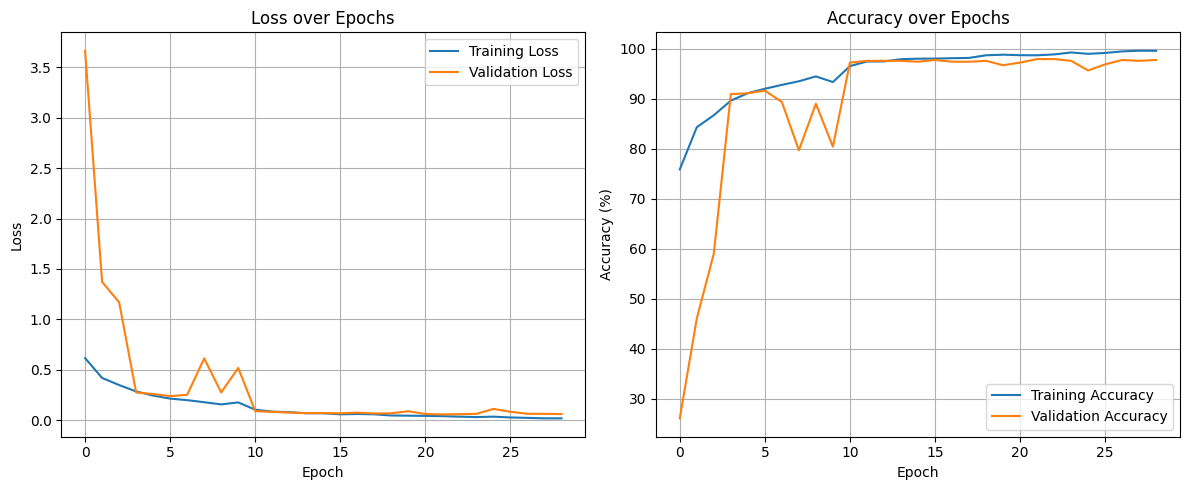

In [ ]:
import torch
import matplotlib.pyplot as plt


num_epochs = 50
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Starting training on {device} for {num_epochs} epochs...")


train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []


for epoch in range(num_epochs):


    model.train()
    running_train_loss = 0.0
    correct_train_predictions = 0
    total_train_samples = 0

    for batch_idx, (images, labels) in enumerate(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        # Convert one-hot labels → class indices
        target_labels_indices = torch.argmax(labels, dim=1)

        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Loss
        loss = criterion(outputs, target_labels_indices)

        # Backward pass
        loss.backward()
        optimizer.step()

        # Loss accumulation
        running_train_loss += loss.item() * images.size(0)

        # Accuracy
        _, predicted = torch.max(outputs, 1)
        total_train_samples += labels.size(0)
        correct_train_predictions += (predicted == target_labels_indices).sum().item()

        # Progress display
        print(
            f"\rEpoch {epoch+1}/{num_epochs} "
            f"| Batch {batch_idx+1}/{len(train_loader)} "
            f"| Train Loss: {running_train_loss/total_train_samples:.4f} "
            f"| Train Acc: {100 * correct_train_predictions/total_train_samples:.2f}%",
            end=""
        )

    # Epoch training metrics
    epoch_train_loss = running_train_loss / total_train_samples
    epoch_train_accuracy = correct_train_predictions / total_train_samples

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_accuracy)


    model.eval()
    running_val_loss = 0.0
    correct_val_predictions = 0
    total_val_samples = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            target_labels_indices = torch.argmax(labels, dim=1)

            outputs = model(images)
            loss = criterion(outputs, target_labels_indices)

            running_val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            total_val_samples += labels.size(0)
            correct_val_predictions += (predicted == target_labels_indices).sum().item()

    epoch_val_loss = running_val_loss / total_val_samples
    epoch_val_accuracy = correct_val_predictions / total_val_samples

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_accuracy)

    scheduler.step(epoch_val_loss)


    epoch_summary = (
        f"\rEpoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Acc: {100*epoch_train_accuracy:.2f}% | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Acc: {100*epoch_val_accuracy:.2f}% | "
        f"LR: {optimizer.param_groups[0]['lr']:.6f}"
    )


    if early_stopping(epoch_val_loss):
        print(epoch_summary + f" | Early stopping triggered")
        break
    else:
        print(epoch_summary + f" | Patience: {early_stopping.counter}/{early_stopping.patience}", end="")

print("\nTraining finished.")


plt.figure(figsize=(12, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss over Epochs")
plt.legend()
plt.grid(True)

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot([acc * 100 for acc in train_accuracies], label="Training Accuracy")
plt.plot([acc * 100 for acc in val_accuracies], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy over Epochs")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:

model.eval()  # Set model to evaluation mode

running_test_loss = 0.0
correct_test_predictions = 0
total_test_samples = 0

with torch.no_grad():  # Disable gradient computation
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Convert one-hot labels → class indices
        target_labels_indices = torch.argmax(labels, dim=1)

        # Forward pass
        outputs = model(images)

        # Loss calculation
        loss = criterion(outputs, target_labels_indices)

        running_test_loss += loss.item() * images.size(0)

        # Accuracy calculation
        _, predicted = torch.max(outputs, 1)
        total_test_samples += labels.size(0)
        correct_test_predictions += (predicted == target_labels_indices).sum().item()


test_loss = running_test_loss / total_test_samples
test_accuracy = correct_test_predictions / total_test_samples

print("\nTesting finished.")
print(f"Final Test Loss: {test_loss:.4f}")
print(f"Final Test Accuracy: {100 * test_accuracy:.2f}%")



Testing finished.
Final Test Loss: 0.0892
Final Test Accuracy: 97.18%


In [ ]:

import numpy as np


model.eval()

running_test_loss = 0.0
correct_test_predictions = 0
total_test_samples = 0

# ✅ Initialize storage lists
all_predictions = []
all_true_labels = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # One-hot → class indices
        true_class_indices = torch.argmax(labels, dim=1)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, true_class_indices)

        running_test_loss += loss.item() * images.size(0)

        # Predicted class
        _, predicted = torch.max(outputs, 1)

        total_test_samples += labels.size(0)
        correct_test_predictions += (predicted == true_class_indices).sum().item()

        # ✅ Store predictions & true labels (move to CPU)
        all_predictions.extend(predicted.cpu().numpy())
        all_true_labels.extend(true_class_indices.cpu().numpy())


test_loss = running_test_loss / total_test_samples
test_accuracy = correct_test_predictions / total_test_samples

print("\nTesting finished.")
print(f"Final Test Loss: {test_loss:.4f}")
print(f"Final Test Accuracy: {100 * test_accuracy:.2f}%")


all_predictions = np.array(all_predictions)
all_true_labels = np.array(all_true_labels)

print(f"Shape of all_predictions: {all_predictions.shape}")
print(f"Shape of all_true_labels: {all_true_labels.shape}")



Testing finished.
Final Test Loss: 0.0892
Final Test Accuracy: 97.18%
Shape of all_predictions: (1311,)
Shape of all_true_labels: (1311,)


Confusion Matrix:
[[284  16   0   0]
 [  7 290   5   4]
 [  2   1 402   0]
 [  0   2   0 298]]


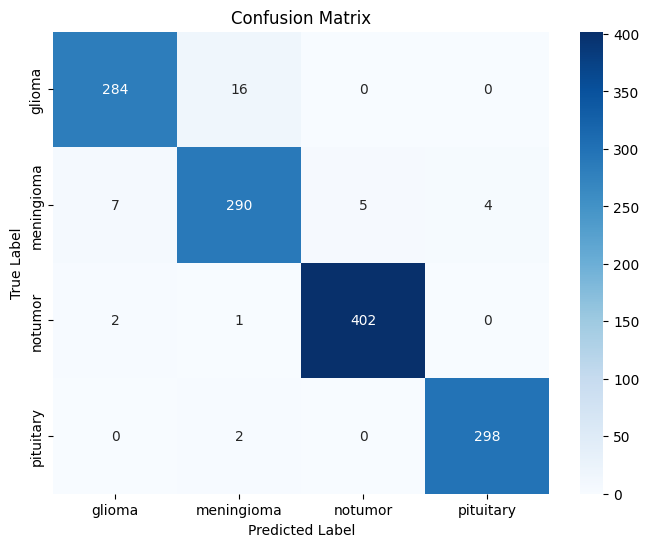


Classification Report:
              precision    recall  f1-score   support

      glioma       0.97      0.95      0.96       300
  meningioma       0.94      0.95      0.94       306
     notumor       0.99      0.99      0.99       405
   pituitary       0.99      0.99      0.99       300

    accuracy                           0.97      1311
   macro avg       0.97      0.97      0.97      1311
weighted avg       0.97      0.97      0.97      1311



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Generate the confusion matrix
cm = confusion_matrix(all_true_labels, all_predictions)

# Print the confusion matrix
print("Confusion Matrix:")
print(cm)

# Plot the confusion matrix for better visualization
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Generate and print the classification report
# class_names is available from CELL 4
print("\nClassification Report:")
print(classification_report(all_true_labels, all_predictions, target_names=class_names))

Confusion Matrix (Row-Normalized - Recall %):
Each row shows, for a given true class, the percentage of predictions for each class.


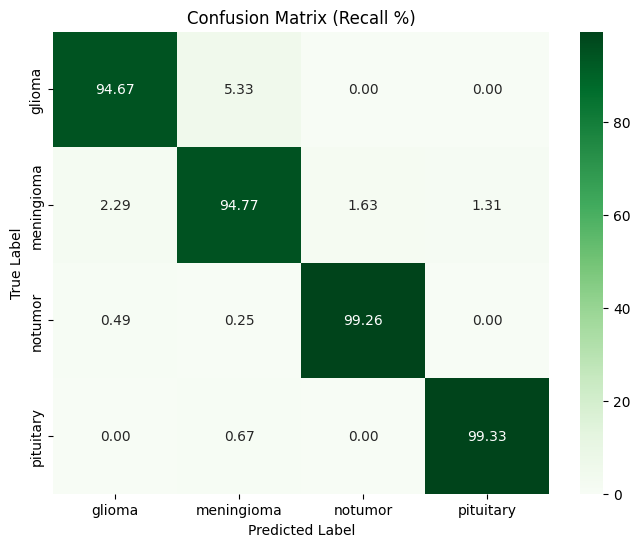


Confusion Matrix (Column-Normalized - Precision %):
Each column shows, for a given predicted class, the percentage of true classes.


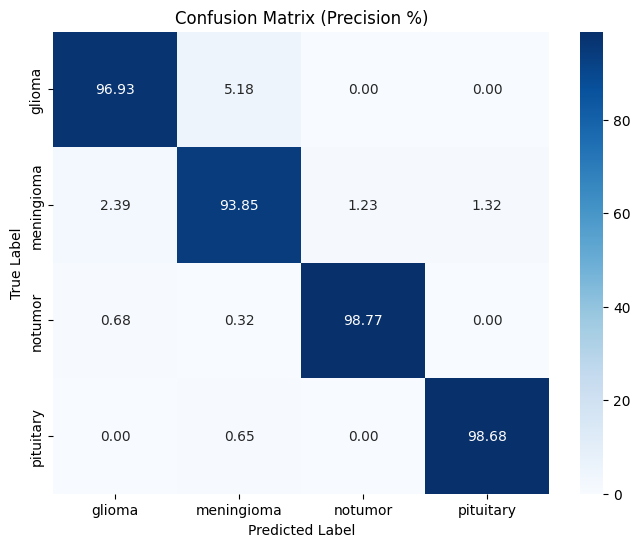


Overall Accuracy from Confusion Matrix: 97.18%


In [ ]:
# Calculate row-wise percentages (Recall/Sensitivity)
# Each row sums to 100%, showing what percentage of actual class X was predicted as Y.
cm_row_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

print("Confusion Matrix (Row-Normalized - Recall %):")
print("Each row shows, for a given true class, the percentage of predictions for each class.")
plt.figure(figsize=(8, 6))
sns.heatmap(cm_row_normalized, annot=True, fmt='.2f', cmap='Greens', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (Recall %)')
plt.show()

# Calculate column-wise percentages (Precision)
# Each column sums to 100%, showing what percentage of predictions for class X were actually class Y.
cm_col_normalized = cm.astype('float') / cm.sum(axis=0)[np.newaxis, :] * 100

print("\nConfusion Matrix (Column-Normalized - Precision %):")
print("Each column shows, for a given predicted class, the percentage of true classes.")
plt.figure(figsize=(8, 6))
sns.heatmap(cm_col_normalized, annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (Precision %)')
plt.show()

# Overall Accuracy (already calculated in CELL 15, but can be derived from CM)
overall_accuracy_cm = np.trace(cm) / np.sum(cm) * 100
print(f"\nOverall Accuracy from Confusion Matrix: {overall_accuracy_cm:.2f}%")

In [ ]:
accuracy = (cm.trace() / cm.sum()) * 100
print(f"Overall Test Accuracy: {accuracy:.2f}%")

Overall Test Accuracy: 97.18%


In [ ]:
torch.save(model.state_dict(), "brain_tumor_cnn_best.pth")
print("Best model saved successfully")

Best model saved successfully


In [ ]:
def get_brain_mask(mri, threshold=0.1):
    mask = mri > threshold
    mask = mask.astype(np.uint8)

    kernel = np.ones((5, 5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

    return mask


def get_tumor_mask(cam, threshold=0.8):
    cam_norm = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam_norm > threshold


def plot_gradcam_overlay(mri, cam, title="Grad-CAM Overlay"):
    plt.figure(figsize=(5, 5))
    plt.imshow(mri, cmap="gray")
    plt.imshow(cam, cmap="jet", alpha=0.5)
    plt.title(title)
    plt.axis("off")
    plt.show()


In [ ]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_backward_hook(backward_hook)

    def generate(self, image, class_idx):
        self.model.zero_grad()
        output = self.model(image)

        score = output[:, class_idx]
        score.backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1)

        cam = torch.relu(cam)
        cam = cam[0].cpu().numpy()

        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        cam = cv2.resize(cam, (image.shape[3], image.shape[2]))

        return cam


In [ ]:
def get_last_conv_layer(model):
    last_conv = None
    for layer in model.modules():
        if isinstance(layer, torch.nn.Conv2d):
            last_conv = layer
    return last_conv


In [ ]:
model.to(device)
model.eval()

target_layer = get_last_conv_layer(model)

if target_layer is None:
    raise ValueError("No Conv2d layer found in the model!")

gradcam = GradCAM(model, target_layer)

print("Grad-CAM initialized with:", target_layer)


Grad-CAM initialized with: Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)


In [ ]:
class_names = train_dataset.classes
selected_indices_per_class = {}

for i, (_, label_one_hot) in enumerate(test_dataset_torch):
    idx = torch.argmax(label_one_hot).item()
    name = class_names[idx]

    if name not in selected_indices_per_class:
        selected_indices_per_class[name] = i

    if len(selected_indices_per_class) == len(class_names):
        break

print("Selected indices:", selected_indices_per_class)


Selected indices: {'glioma': 0, 'meningioma': 300, 'notumor': 606, 'pituitary': 1011}


In [ ]:

!pip install opencv-python

import cv2
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt



=== Case 1 | Class: glioma ===


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:1866: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


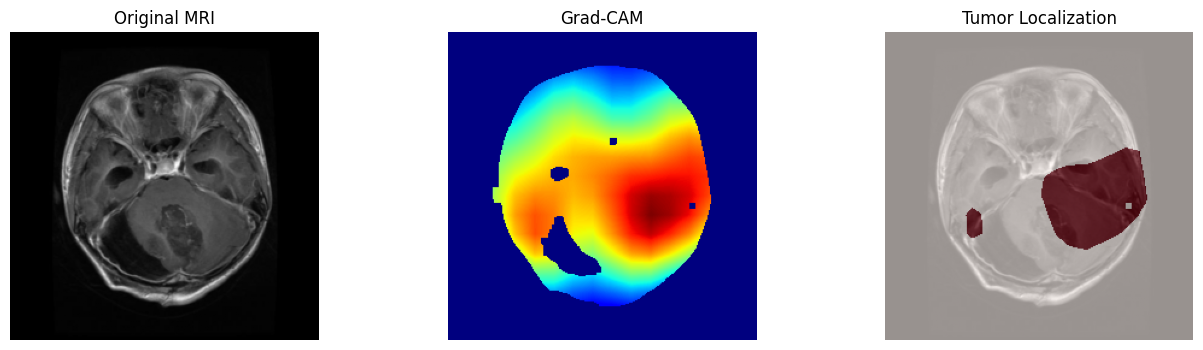

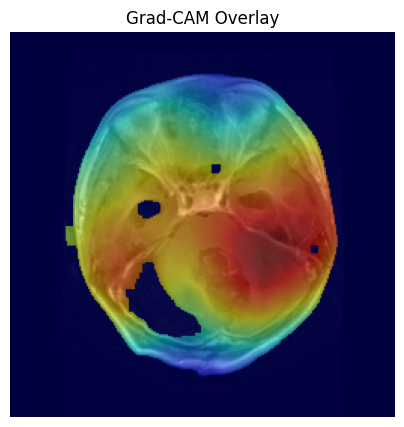

True Class      : glioma
Predicted Class : glioma
Confidence      : 99.95%

=== Case 2 | Class: meningioma ===


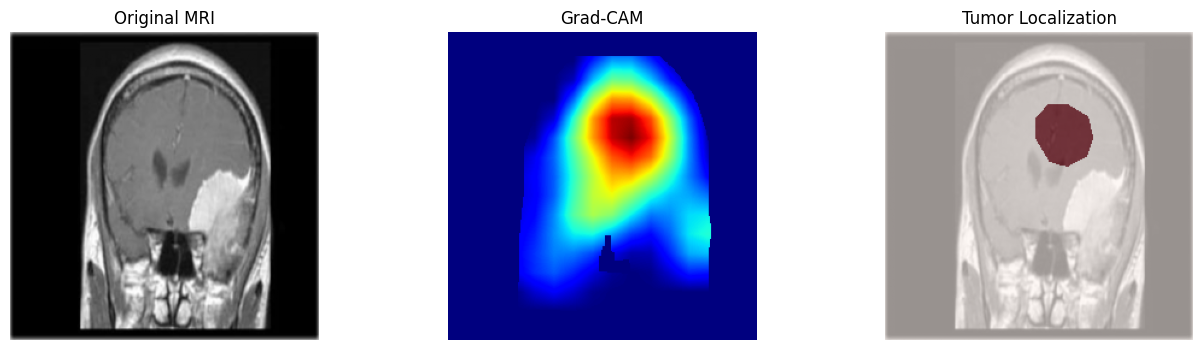

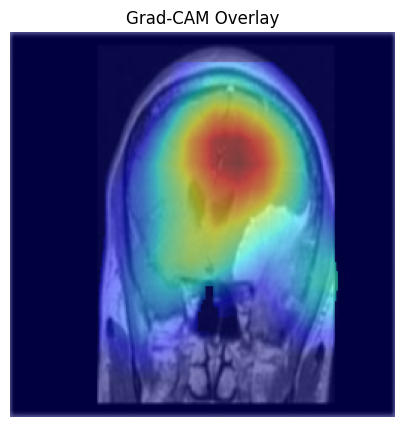

True Class      : meningioma
Predicted Class : meningioma
Confidence      : 96.24%

=== Case 3 | Class: notumor ===


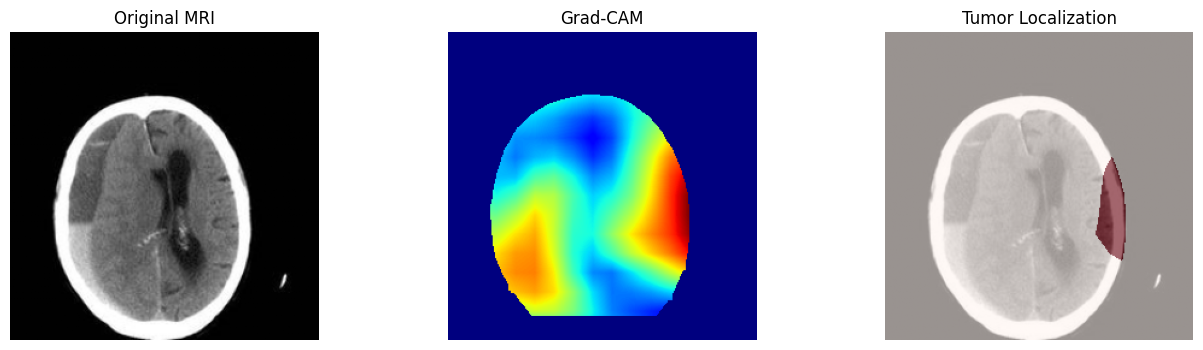

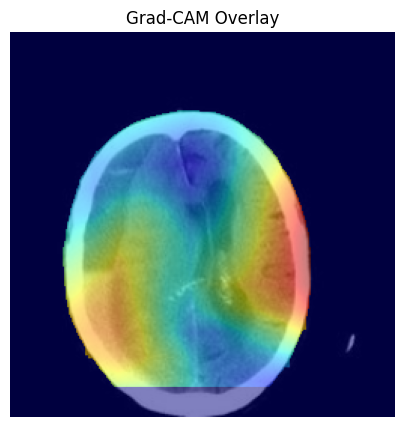

True Class      : notumor
Predicted Class : notumor
Confidence      : 99.88%

=== Case 4 | Class: pituitary ===


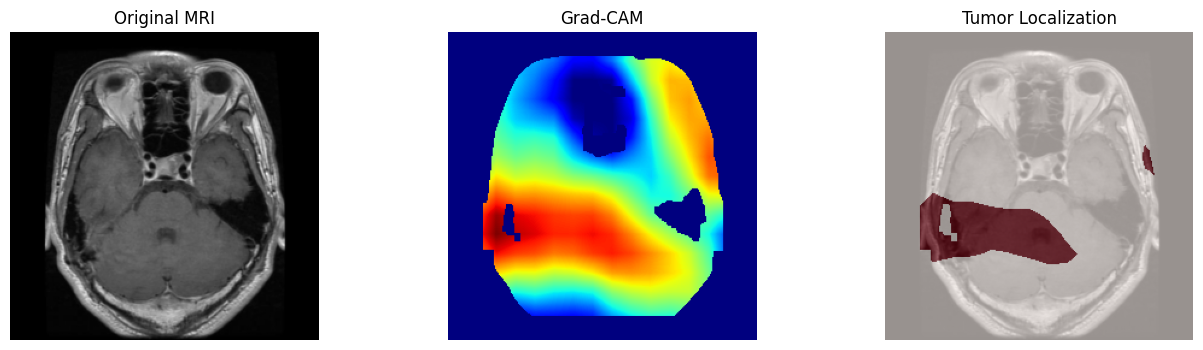

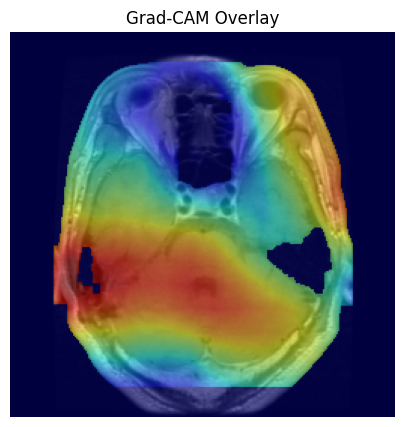

True Class      : pituitary
Predicted Class : pituitary
Confidence      : 99.02%


In [ ]:
case_counter = 1

for class_name, test_idx in selected_indices_per_class.items():

    print(f"\n=== Case {case_counter} | Class: {class_name} ===")

    image_tensor, label_one_hot = test_dataset_torch[test_idx]
    true_idx = torch.argmax(label_one_hot).item()
    true_name = class_names[true_idx]

    image = image_tensor.unsqueeze(0).to(device)

    mri = image[0, 0].cpu().numpy()
    mri = (mri - mri.min()) / (mri.max() - mri.min() + 1e-8)

    brain_mask = get_brain_mask(mri)

    cam = gradcam.generate(image, class_idx=true_idx)

    cam[:20, :] = 0
    cam[-20:, :] = 0
    cam[:, :20] = 0
    cam[:, -20:] = 0

    cam_brain = cam * brain_mask

    with torch.no_grad():
        logits = model(image)
        probs = F.softmax(logits, dim=1)
        pred_idx = torch.argmax(logits, dim=1).item()
        pred_name = class_names[pred_idx]
        conf = probs[0, pred_idx].item() * 100

    plt.figure(figsize=(16, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(mri, cmap="gray")
    plt.title("Original MRI")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(cam_brain, cmap="jet")
    plt.title("Grad-CAM")
    plt.axis("off")

    tumor_mask = get_tumor_mask(cam_brain)

    plt.subplot(1, 3, 3)
    plt.imshow(mri, cmap="gray")
    plt.imshow(tumor_mask, cmap="Reds", alpha=0.6)
    plt.title("Tumor Localization")
    plt.axis("off")

    plt.show()

    plot_gradcam_overlay(mri, cam_brain)

    print(f"True Class      : {true_name}")
    print(f"Predicted Class : {pred_name}")
    print(f"Confidence      : {conf:.2f}%")

    case_counter += 1


In [ ]:
!pip install lime


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 10.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=14310fd692235ac9693624367d56782aea769906464c8255ef633ae33d554e3b
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


In [ ]:
from lime import lime_image
from skimage.segmentation import slic, mark_boundaries
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
explainer = lime_image.LimeImageExplainer()


lime


In [ ]:
def lime_predict(images):
    """
    images: (N, H, W, 3) from LIME
    model expects: (N, 1, H, W)
    """
    model.eval()

    # Convert RGB -> grayscale
    images_gray = images.mean(axis=-1)          # (N, H, W)

    # ✅ FIX: add ONLY ONE channel dimension
    images_gray = torch.tensor(images_gray).float().unsqueeze(1).to(device)
    # Shape now: (N, 1, H, W)

    with torch.no_grad():
        outputs = model(images_gray)
        probs = F.softmax(outputs, dim=1)

    return probs.cpu().numpy()


In [ ]:
def lime_predict(images):
    """
    Handles all LIME input shapes safely.
    Final tensor sent to model: (N, 1, H, W)
    """
    model.eval()

    # Convert to numpy array
    images = np.array(images)

    # 🔥 FIX 1: If LIME sends (N, 1, H, W, 3), squeeze it
    if images.ndim == 5:
        images = images.squeeze(1)   # (N, H, W, 3)

    # RGB → grayscale
    images_gray = images.mean(axis=-1)  # (N, H, W)

    # 🔥 FIX 2: Ensure exactly ONE channel
    images_gray = torch.tensor(images_gray).float().unsqueeze(1).to(device)
    # Shape guaranteed: (N, 1, H, W)

    with torch.no_grad():
        outputs = model(images_gray)
        probs = F.softmax(outputs, dim=1)

    return probs.cpu().numpy()


  0%|          | 0/1000 [00:00<?, ?it/s]

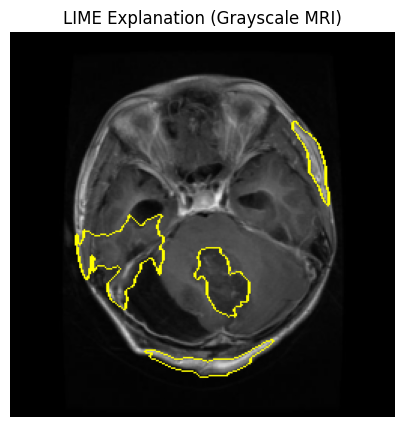

In [ ]:
image_gray = x_test[0]
image_rgb = np.stack([image_gray]*3, axis=-1)

def slic_segmentation(image):
    return slic(image, n_segments=100, compactness=10, sigma=1, channel_axis=-1)

explanation = explainer.explain_instance(
    image_rgb,
    lime_predict,
    top_labels=1,
    hide_color=0,
    num_samples=1000,
    segmentation_fn=slic_segmentation
)

temp, mask = explanation.get_image_and_mask(
    explanation.top_labels[0],
    positive_only=True,
    hide_rest=False
)
# 🔥 FIX: remove batch dimension if present
if temp.ndim == 4:
    temp = temp[0]
if mask.ndim == 3:
    mask = mask[0]

plt.figure(figsize=(5, 5))
plt.imshow(mark_boundaries(temp, mask))
plt.title("LIME Explanation (Grayscale MRI)")
plt.axis("off")
plt.show()





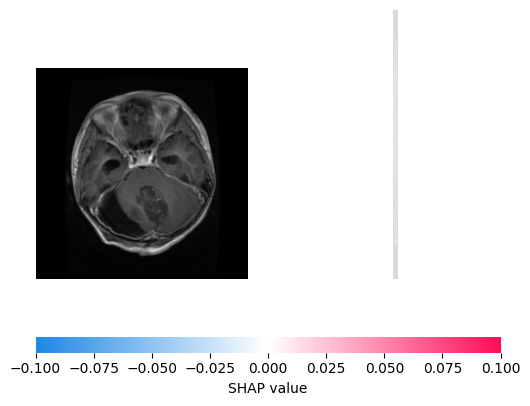

In [ ]:
# =========================
# SHAP FOR FEATURE OUTPUT MODEL (FIXED)
# =========================

!pip install -q shap

import torch
import shap
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.eval()

# -------------------------
# 1️⃣ Get one test image
# -------------------------
test_img, _ = next(iter(test_loader))
test_img = test_img.to(device)           # (1, 1, H, W)

test_img_np = test_img.cpu().numpy()[0, 0]

# -------------------------
# 2️⃣ Background images
# -------------------------
background_imgs, _ = next(iter(test_loader))
background_imgs = background_imgs[:10].to(device)

# -------------------------
# 3️⃣ SHAP Gradient Explainer
# -------------------------
explainer = shap.GradientExplainer(
    model,
    background_imgs
)

# -------------------------
# 4️⃣ Compute SHAP values
# -------------------------
shap_values = explainer.shap_values(test_img)

# -------------------------
# 5️⃣ Select ONE feature neuron
# -------------------------
feature_idx = 0   # explain neuron 0

# SHAP shape: (1, 1, H, W)
shap_map = shap_values[feature_idx][0, 0]

# -------------------------
# 6️⃣ Prepare RGB for plotting
# -------------------------
shap_rgb = np.stack([shap_map]*3, axis=-1)
img_rgb  = np.stack([test_img_np]*3, axis=-1)

shap_np   = np.expand_dims(shap_rgb, axis=0)
images_np = np.expand_dims(img_rgb, axis=0)

# -------------------------
# 7️⃣ Plot
# -------------------------
shap.image_plot(shap_np, images_np)


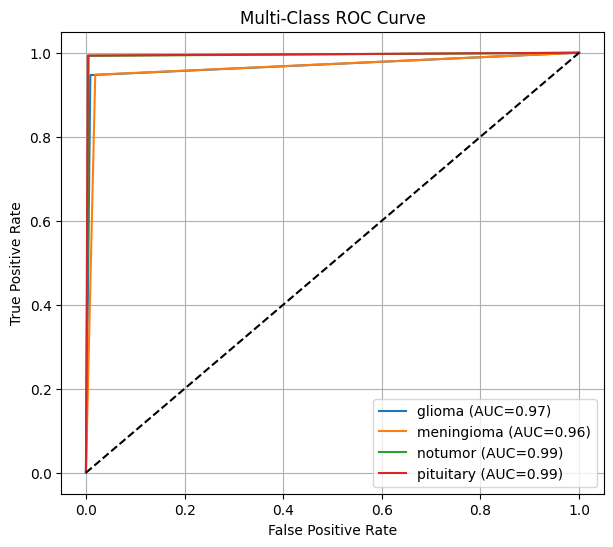

In [ ]:


from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Convert labels to one-hot
y_true_bin = label_binarize(all_true_labels, classes=range(num_classes))
y_pred_bin = label_binarize(all_predictions, classes=range(num_classes))

plt.figure(figsize=(7, 6))

for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_bin[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC={roc_auc:.2f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-Class ROC Curve")
plt.legend()
plt.grid(True)
plt.show()


TEST-TIME AUGMENTATION

In [ ]:

def tta_predict(model, image):
    model.eval()
    preds = []

    transforms_list = [
        lambda x: x,
        lambda x: torch.flip(x, dims=[2]),
        lambda x: torch.flip(x, dims=[3])
    ]

    with torch.no_grad():
        for t in transforms_list:
            out = model(t(image))
            preds.append(F.softmax(out, dim=1))

    return torch.mean(torch.stack(preds), dim=0)


In [ ]:
import random, numpy as np, torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


In [ ]:
# Save model weights
torch.save(model.state_dict(), "brain_tumor_cnn_frozen.pth")
print("Model saved as brain_tumor_cnn_frozen.pth")


Model saved as brain_tumor_cnn_frozen.pth


In [ ]:
!pip freeze > requirements.txt
print("requirements.txt saved")


requirements.txt saved
